In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
Mounted at /content/drive


In [ ]:
# ============================================================
# PHISHGUARD — CORRECTED PHISHING-CLASS METRICS
# NO RETRAINING REQUIRED
# PhiUSIIL: 0 = Phishing, 1 = Legitimate
# ============================================================

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. LOAD SAVED PROBABILITIES AND LABELS
# ------------------------------------------------------------

d_probs = np.load(
    "/content/drive/MyDrive/distilbert_phishing_probabilities.npy"
)

r_probs = np.load(
    "/content/drive/MyDrive/roberta_phishing_probabilities.npy"
)

db_probs = np.load(
    "/content/drive/MyDrive/deberta_phishing_probabilities.npy"
)

labels = np.load(
    "/content/drive/MyDrive/ensemble_test_labels.npy"
)

print("Loaded arrays:")
print("DistilBERT:", len(d_probs))
print("RoBERTa   :", len(r_probs))
print("DeBERTa   :", len(db_probs))
print("Labels    :", len(labels))


# ------------------------------------------------------------
# 2. RECREATE THE EXACT VALIDATION / FINAL TEST SPLIT
# ------------------------------------------------------------

indices = np.arange(len(labels))

val_idx, final_idx = train_test_split(
    indices,
    test_size=0.50,
    random_state=42,
    stratify=labels
)

y_original = labels[final_idx]

d_final = d_probs[final_idx]
r_final = r_probs[final_idx]
db_final = db_probs[final_idx]


# ------------------------------------------------------------
# 3. IMPORTANT:
# SAVED "phishing_probabilities" ARE ACTUALLY CLASS-1
# PROBABILITIES.
#
# PhiUSIIL:
#   Class 0 = Phishing
#   Class 1 = Legitimate
#
# Therefore:
# phishing_probability = 1 - class1_probability
# ------------------------------------------------------------

d_phishing_prob = 1 - d_final
r_phishing_prob = 1 - r_final
db_phishing_prob = 1 - db_final

# Convert true labels:
# 0 = phishing -> 1
# 1 = legitimate -> 0

y_phishing = (y_original == 0).astype(int)


# ------------------------------------------------------------
# 4. INDIVIDUAL MODEL METRICS
# ------------------------------------------------------------

models = {
    "DistilBERT": d_phishing_prob,
    "RoBERTa": r_phishing_prob,
    "DeBERTa-v3-small": db_phishing_prob
}

results = {}

for name, phishing_prob in models.items():

    pred_phishing = (
        phishing_prob >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        y_phishing,
        pred_phishing
    )

    precision = precision_score(
        y_phishing,
        pred_phishing,
        zero_division=0
    )

    recall = recall_score(
        y_phishing,
        pred_phishing,
        zero_division=0
    )

    f1 = f1_score(
        y_phishing,
        pred_phishing,
        zero_division=0
    )

    cm = confusion_matrix(
        y_phishing,
        pred_phishing
    )

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "CM": cm
    }


# ------------------------------------------------------------
# 5. CORRECTED WEIGHTED ENSEMBLE
# ------------------------------------------------------------

w_distilbert = 0.58
w_roberta = 0.35
w_deberta = 0.07

ensemble_phishing_probability = (
    w_distilbert * d_phishing_prob
    + w_roberta * r_phishing_prob
    + w_deberta * db_phishing_prob
)

ensemble_prediction = (
    ensemble_phishing_probability >= 0.5
).astype(int)


ensemble_accuracy = accuracy_score(
    y_phishing,
    ensemble_prediction
)

ensemble_precision = precision_score(
    y_phishing,
    ensemble_prediction,
    zero_division=0
)

ensemble_recall = recall_score(
    y_phishing,
    ensemble_prediction,
    zero_division=0
)

ensemble_f1 = f1_score(
    y_phishing,
    ensemble_prediction,
    zero_division=0
)

ensemble_cm = confusion_matrix(
    y_phishing,
    ensemble_prediction
)


# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("        PHISHGUARD — CORRECTED PHISHING METRICS")
print("=" * 70)

for name, r in results.items():

    print(f"\n{name}")
    print("-" * 40)

    print(f"Accuracy  : {r['Accuracy']:.6f}")
    print(f"Precision : {r['Precision']:.6f}")
    print(f"Recall    : {r['Recall']:.6f}")
    print(f"F1 Score  : {r['F1']:.6f}")

    print("\nConfusion Matrix:")
    print(r["CM"])


print("\n")
print("=" * 70)
print("        PHISHGUARD WEIGHTED ENSEMBLE")
print("=" * 70)

print(f"Accuracy  : {ensemble_accuracy:.6f}")
print(f"Precision : {ensemble_precision:.6f}")
print(f"Recall    : {ensemble_recall:.6f}")
print(f"F1 Score  : {ensemble_f1:.6f}")

print("\nConfusion Matrix:")
print(ensemble_cm)


# ------------------------------------------------------------
# 7. PERCENTAGE TABLE
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("FINAL RESULTS — PHISHING AS POSITIVE CLASS")
print("=" * 80)

print(
    f"{'Model':<30}"
    f"{'Accuracy':>12}"
    f"{'Precision':>12}"
    f"{'Recall':>12}"
    f"{'F1':>12}"
)

print("-" * 80)

for name, r in results.items():

    print(
        f"{name:<30}"
        f"{r['Accuracy']*100:>11.2f}%"
        f"{r['Precision']*100:>11.2f}%"
        f"{r['Recall']*100:>11.2f}%"
        f"{r['F1']*100:>11.2f}%"
    )

print(
    f"{'PhishGuard Weighted Ensemble':<30}"
    f"{ensemble_accuracy*100:>11.2f}%"
    f"{ensemble_precision*100:>11.2f}%"
    f"{ensemble_recall*100:>11.2f}%"
    f"{ensemble_f1*100:>11.2f}%"
)

print("=" * 80)

Loaded arrays:
DistilBERT: 47159
RoBERTa   : 47159
DeBERTa   : 47159
Labels    : 47159


        PHISHGUARD — CORRECTED PHISHING METRICS

DistilBERT
----------------------------------------
Accuracy  : 0.998092
Precision : 0.999900
Recall    : 0.995634
F1 Score  : 0.997762

Confusion Matrix:
[[13502     1]
 [   44 10033]]

RoBERTa
----------------------------------------
Accuracy  : 0.997922
Precision : 0.999900
Recall    : 0.995237
F1 Score  : 0.997563

Confusion Matrix:
[[13502     1]
 [   48 10029]]

DeBERTa-v3-small
----------------------------------------
Accuracy  : 0.997922
Precision : 0.999801
Recall    : 0.995336
F1 Score  : 0.997563

Confusion Matrix:
[[13501     2]
 [   47 10030]]


        PHISHGUARD WEIGHTED ENSEMBLE
Accuracy  : 0.998092
Precision : 0.999900
Recall    : 0.995634
F1 Score  : 0.997762

Confusion Matrix:
[[13502     1]
 [   44 10033]]


FINAL RESULTS — PHISHING AS POSITIVE CLASS
Model                             Accuracy   Precision      Recall          F1
--

In [ ]:
# ==============================
# Import Required Libraries
# ==============================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Display all columns
pd.set_option('display.max_columns', None)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [ ]:
# ==============================
# Load Dataset
# ==============================

df = pd.read_csv('/content/PhiUSIIL_Phishing_URL_Dataset.csv')

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [ ]:
# ==============================
# Display First 5 Rows
# ==============================

df.head()

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [ ]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

Rows : 235795
Columns : 55


In [ ]:
print(df.columns.tolist())

['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 55 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   URL                         235795 non-null  object 
 1   URLLength                   235795 non-null  int64  
 2   Domain                      235795 non-null  object 
 3   DomainLength                235795 non-null  int64  
 4   IsDomainIP                  235795 non-null  int64  
 5   TLD                         235795 non-null  object 
 6   URLSimilarityIndex          235795 non-null  float64
 7   CharContinuationRate        235795 non-null  float64
 8   TLDLegitimateProb           235795 non-null  float64
 9   URLCharProb                 235795 non-null  float64
 10  TLDLength                   235795 non-null  int64  
 11  NoOfSubDomain               235795 non-null  int64  
 12  HasObfuscation              235795 non-null  int64  
 13  NoOfObfuscated

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


In [ ]:
# ==============================
# Missing Values
# ==============================

missing = df.isnull().sum()

missing = missing[missing > 0]

print(missing)

Series([], dtype: int64)


In [ ]:
duplicates = df.duplicated().sum()

print("Duplicate Rows :", duplicates)

Duplicate Rows : 0


In [ ]:
df['label'].value_counts()

,count
label,
1,134850
0,100945


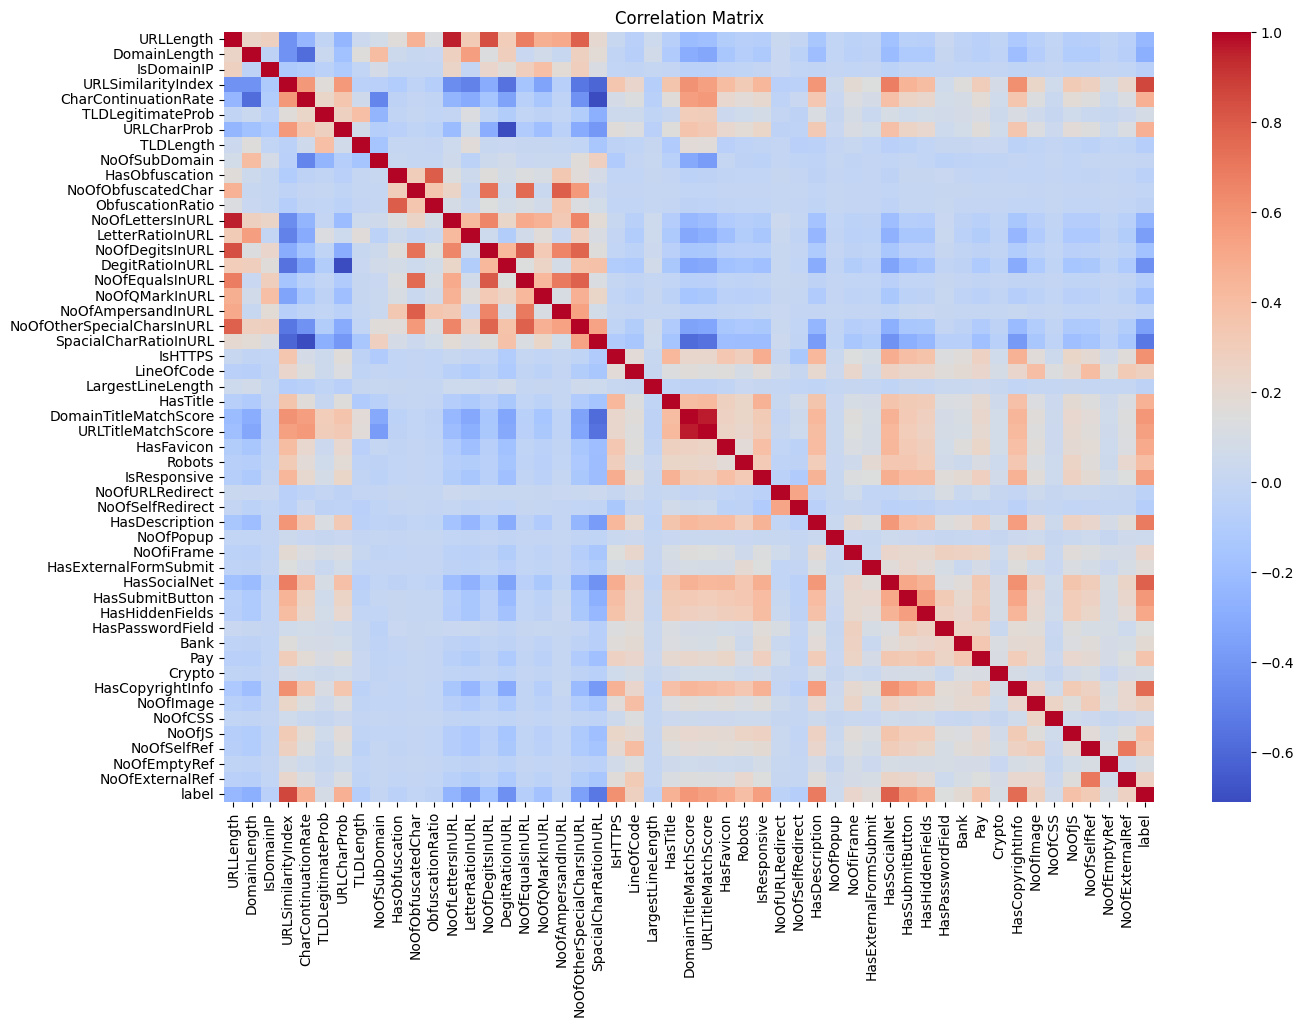

In [ ]:
plt.figure(figsize=(15,10))

sns.heatmap(df.corr(numeric_only=True),
            cmap='coolwarm',
            cbar=True)

plt.title("Correlation Matrix")

plt.show()

In [ ]:
df_clean = df.copy()

print("Working Copy Created Successfully!")

Working Copy Created Successfully!


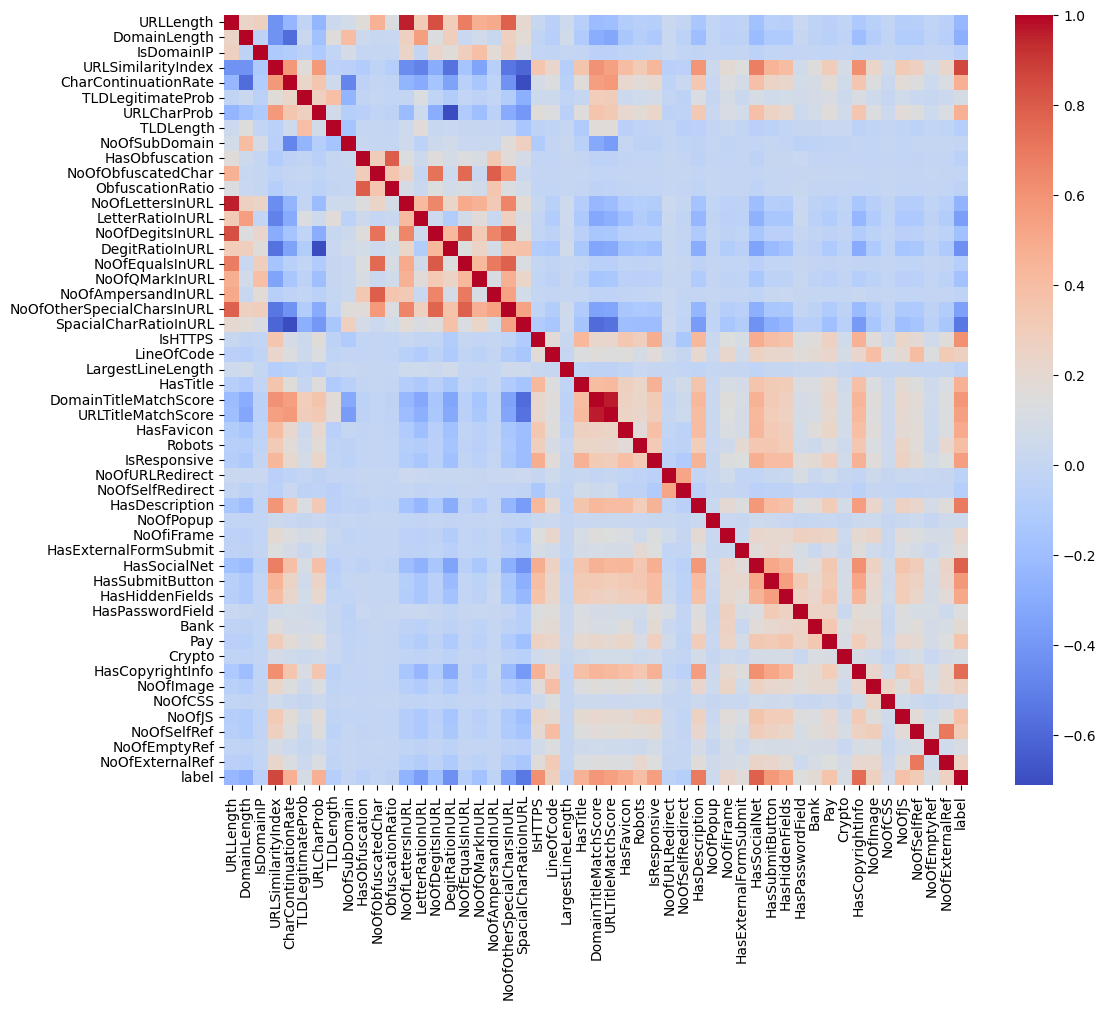

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,10))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm')
plt.show()

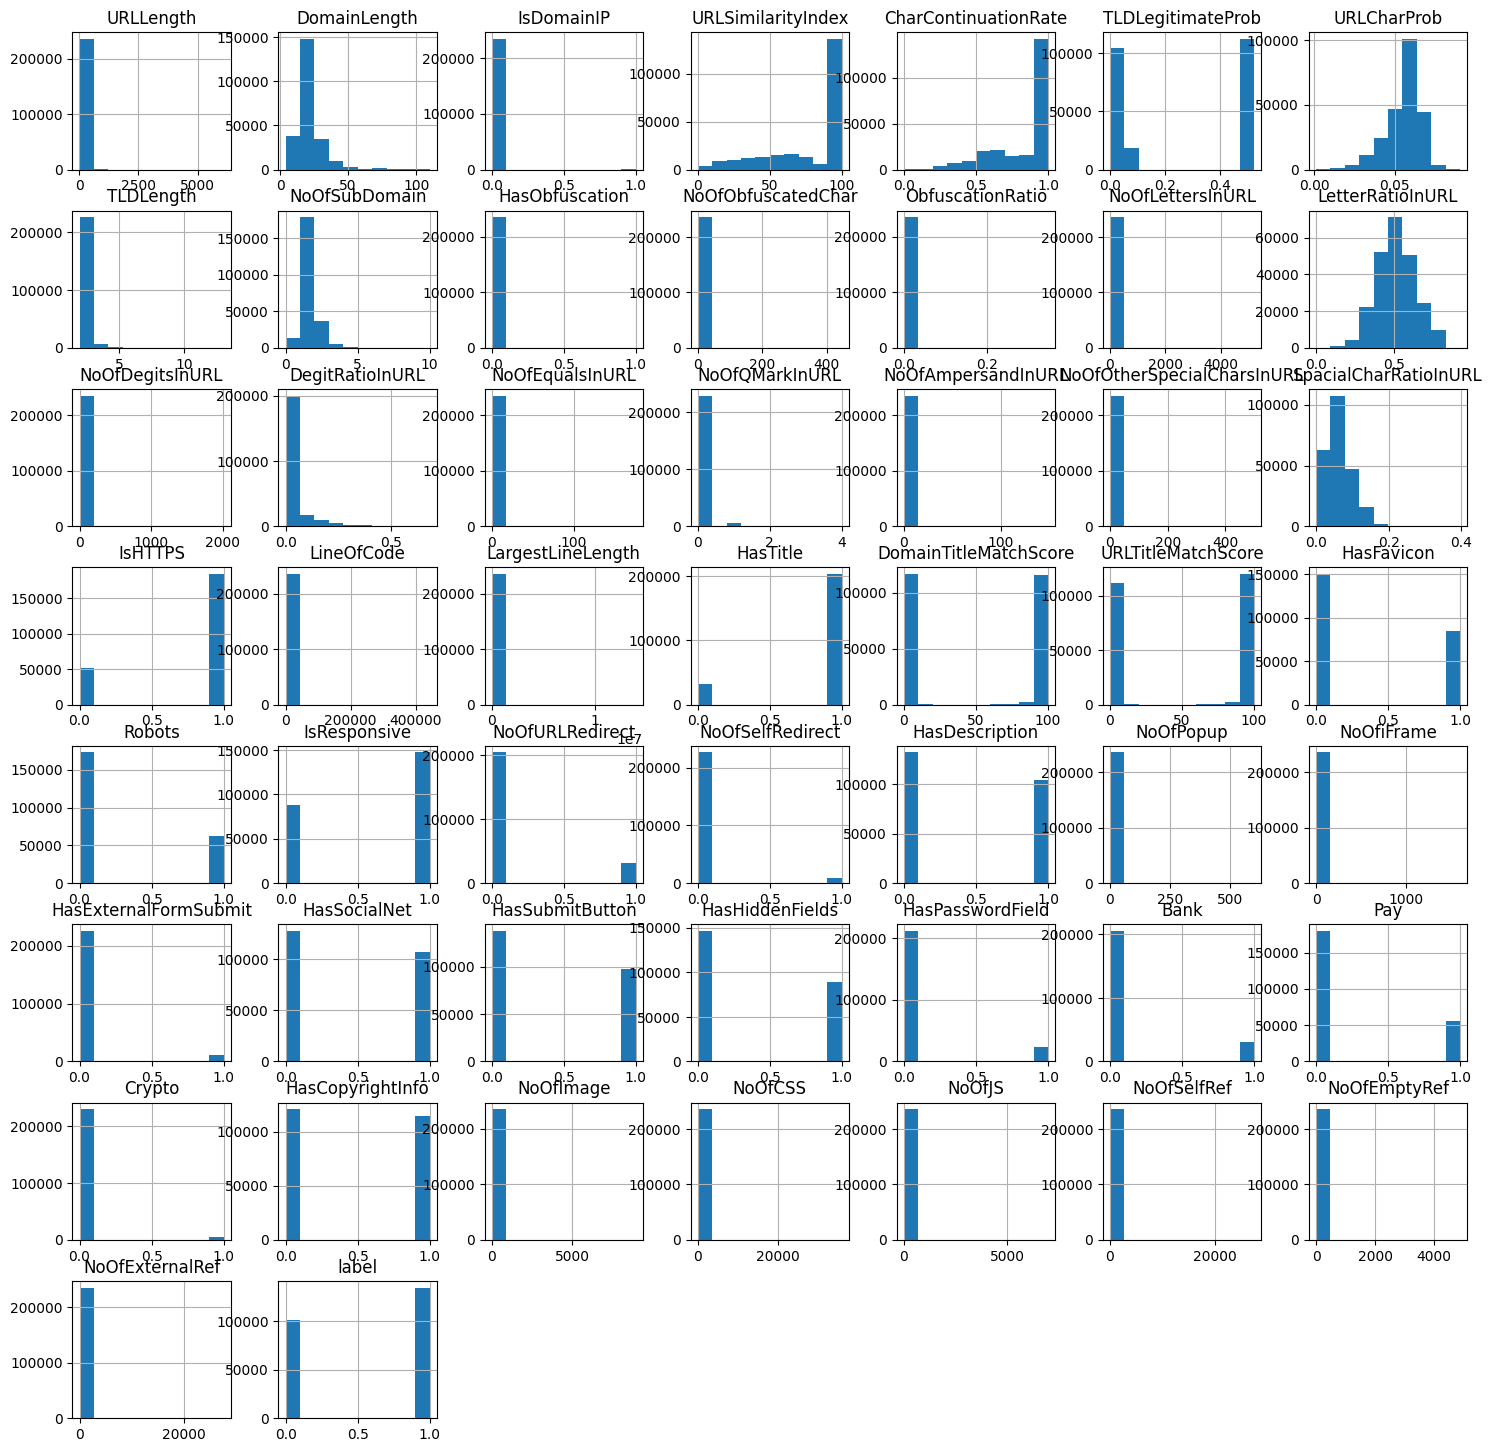

In [ ]:
df.hist(figsize=(18,18))
plt.show()

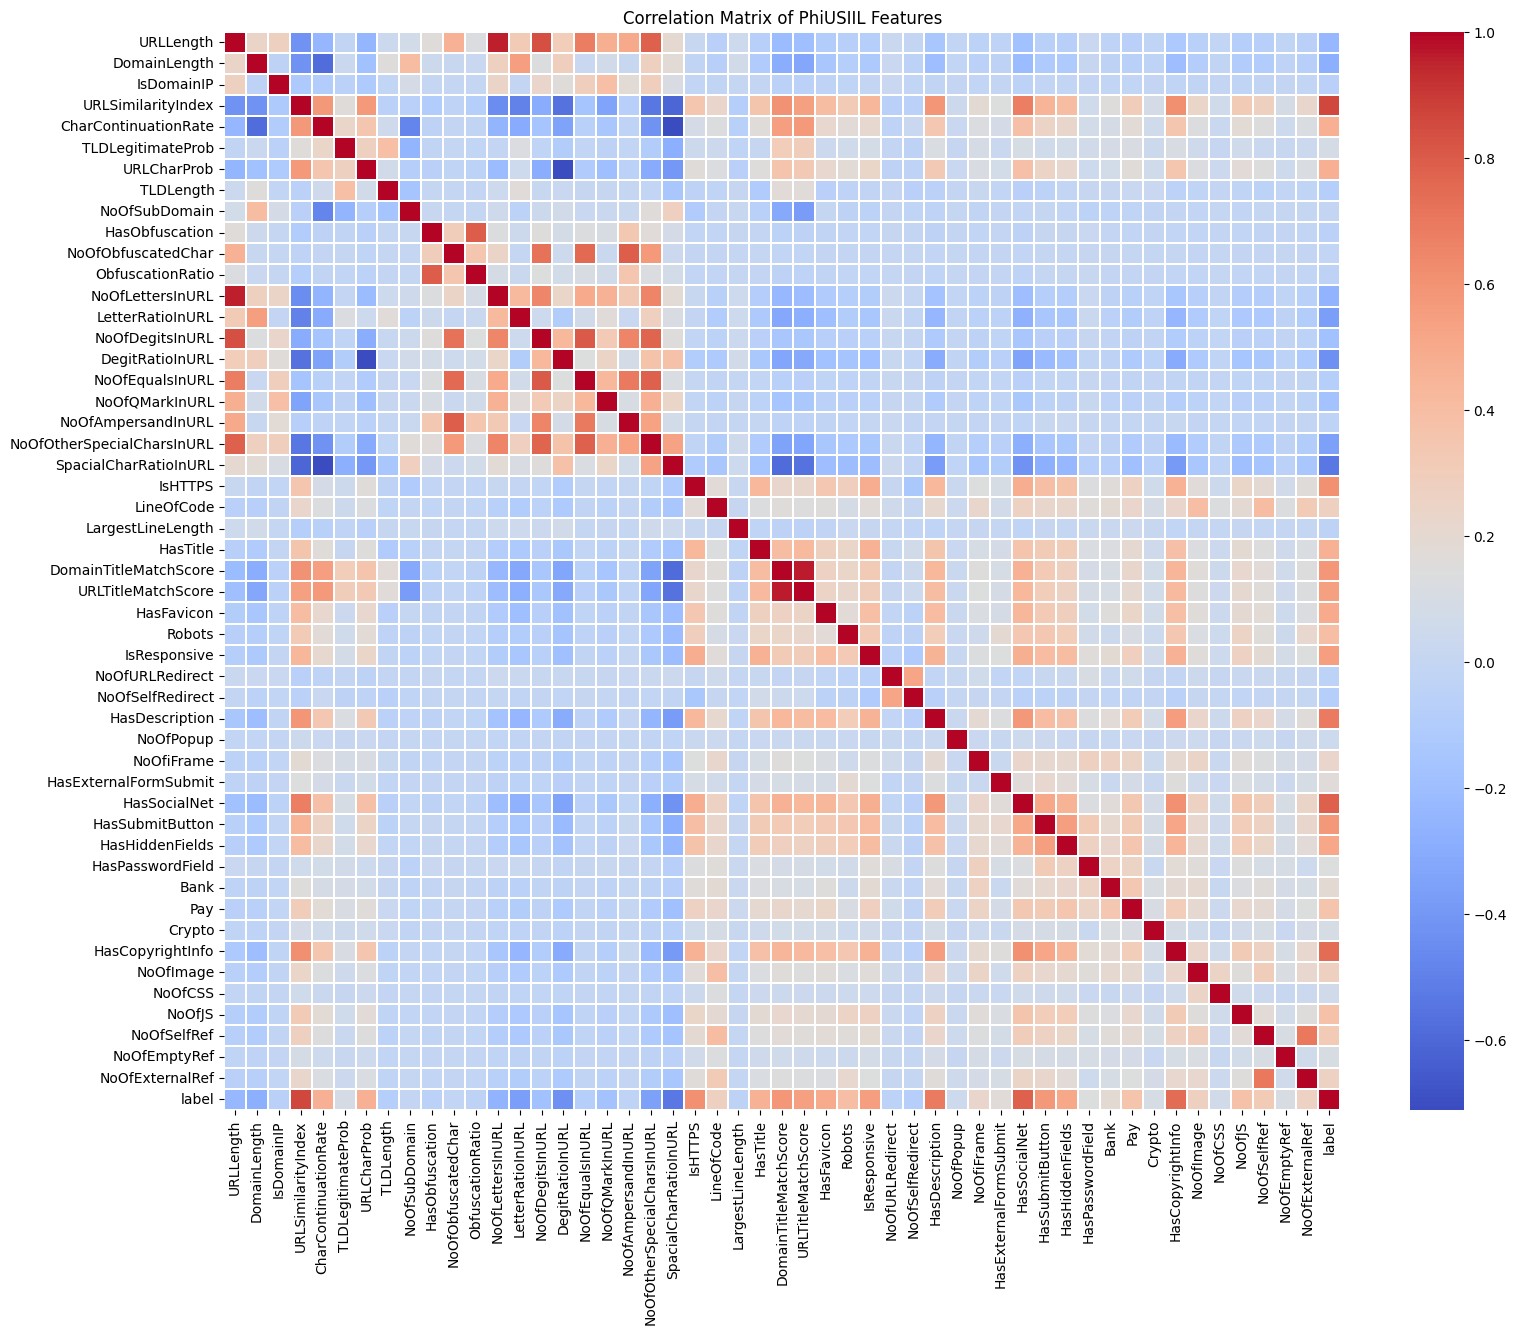

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18,14))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    cmap='coolwarm',
    linewidths=0.3
)

plt.title("Correlation Matrix of PhiUSIIL Features")
plt.show()

In [ ]:
corr_matrix = df.corr(numeric_only=True).abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = [
    column
    for column in upper.columns
    if any(upper[column] > 0.90)
]

print("Highly Correlated Features:")
print(high_corr)

Highly Correlated Features:
['NoOfLettersInURL', 'URLTitleMatchScore']


PHASE 2 TRANSFORMER BASED PHISHING DETECTION


In [ ]:
df[['URL','label']].head(10)

,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1
5,https://www.globalreporting.org,1
6,https://www.saffronart.com,1
7,https://www.nerdscandy.com,1
8,https://www.hyderabadonline.in,1
9,https://www.aap.org,1


In [ ]:
# Create transformer dataset

hf_df = df[['URL', 'label']].copy()

hf_df.columns = ['text', 'label']

hf_df.head()

,text,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1


In [ ]:
hf_df['label'].value_counts()

,count
label,
1,134850
0,100945


In [ ]:
!pip install transformers datasets accelerate evaluate -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.5 MB/s eta 0:00:00


In [ ]:
from datasets import Dataset

# Use the complete dataset
hf_df = df[['URL', 'label']].copy()

# Rename URL column to text for Transformer input
hf_df = hf_df.rename(columns={'URL': 'text'})

# Create Hugging Face Dataset
dataset = Dataset.from_pandas(
    hf_df,
    preserve_index=False
)

print(dataset)

Dataset({
    features: ['text', 'label'],
    num_rows: 235795
})


In [ ]:
print("Total samples:", len(dataset))
print("Features:", dataset.column_names)

print("\nFirst 5 records:")
print(dataset[:5])

Total samples: 235795
Features: ['text', 'label']

First 5 records:
{'text': ['https://www.southbankmosaics.com', 'https://www.uni-mainz.de', 'https://www.voicefmradio.co.uk', 'https://www.sfnmjournal.com', 'https://www.rewildingargentina.org'], 'label': [1, 1, 1, 1, 1]}


In [ ]:
from sklearn.model_selection import train_test_split

dataset_split = dataset.train_test_split(
    test_size=0.20,
    seed=42
)

train_dataset = dataset_split["train"]
test_dataset = dataset_split["test"]

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 188636
Testing samples: 47159


In [ ]:
# from transformers import AutoTokenizer, AutoModelForSequenceClassification

# model_name = "distilbert-base-uncased"

# tokenizer = AutoTokenizer.from_pretrained(model_name)

# model = AutoModelForSequenceClassification.from_pretrained(
#     model_name,
#     num_labels=2
# )

# print("DistilBERT loaded successfully.")

In [ ]:
# ============================================================
# NEXT SESSION — LOAD SAVED FINAL DISTILBERT
# ============================================================

from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification

final_model_path = "/content/drive/MyDrive/distilbert_phishing_full"

tokenizer = AutoTokenizer.from_pretrained(
    final_model_path
)

model = AutoModelForSequenceClassification.from_pretrained(
    final_model_path
)

print("Saved final DistilBERT loaded successfully.")

Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

Saved final DistilBERT loaded successfully.


In [ ]:
# final_model_path = "/content/drive/MyDrive/distilbert_phishing_full"

# model.save_pretrained(final_model_path)
# tokenizer.save_pretrained(final_model_path)

# print("Final DistilBERT model saved successfully.")
# print(final_model_path)

In [ ]:
def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

tokenized_dataset = dataset_split.map(
    tokenize_function,
    batched=True,
    desc="Tokenizing URLs"
)

train_dataset = tokenized_dataset["train"]
test_dataset = tokenized_dataset["test"]

print("Tokenization completed.")

Tokenizing URLs:   0%|          | 0/188636 [00:00<?, ? examples/s]

Tokenizing URLs:   0%|          | 0/47159 [00:00<?, ? examples/s]

Tokenization completed.


In [ ]:
print(train_dataset)
print(test_dataset)

print("\nExample tokenized record:")
print(train_dataset[0])

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 188636
})
Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 47159
})

Example tokenized record:
{'text': 'http://designsubtle.cn/atacadaosabrw/tb.php', 'label': 0, 'input_ids': [101, 8299, 1024, 1013, 1013, 5617, 12083, 9286, 1012, 27166, 1013, 29533, 3540, 2850, 8820, 19892, 2860, 1013, 26419, 1012, 25718, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):

    predictions, labels = eval_pred

    predictions = np.argmax(predictions, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [ ]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./distilbert_full_results",

    num_train_epochs=2,

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    logging_steps=500,

    report_to="none"
)

In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=test_dataset,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Trainer is ready.")

Trainer is ready.


In [ ]:
# trainer.train()

In [ ]:
results = trainer.evaluate()

print("\n===== FINAL DISTILBERT RESULTS =====")

print(f"Accuracy  : {results['eval_accuracy']:.4f}")
print(f"Precision : {results['eval_precision']:.4f}")
print(f"Recall    : {results['eval_recall']:.4f}")
print(f"F1 Score  : {results['eval_f1']:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
No log,0.012297,0,0.998304,0.997156,0.999889,0.998521



===== FINAL DISTILBERT RESULTS =====
Accuracy  : 0.9983
Precision : 0.9972
Recall    : 0.9999
F1 Score  : 0.9985


In [ ]:
# # ============================================================
# # MODEL 2 — RoBERTa
# # ============================================================

# from transformers import (
#     AutoTokenizer,
#     AutoModelForSequenceClassification
# )

# roberta_model_name = "roberta-base"

# roberta_tokenizer = AutoTokenizer.from_pretrained(
#     roberta_model_name
# )

# roberta_model = AutoModelForSequenceClassification.from_pretrained(
#     roberta_model_name,
#     num_labels=2
# )

# print("RoBERTa loaded successfully.")

In [ ]:
# roberta_save_path = "/content/drive/MyDrive/roberta_phishing_full"

# roberta_model.save_pretrained(
#     roberta_save_path
# )

# roberta_tokenizer.save_pretrained(
#     roberta_save_path
# )

# print("RoBERTa model saved successfully.")
# print(roberta_save_path)

In [ ]:
# ============================================================
# NEXT SESSION — LOAD SAVED RoBERTa
# ============================================================

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

roberta_save_path = "/content/drive/MyDrive/roberta_phishing_full"

roberta_tokenizer = AutoTokenizer.from_pretrained(
    roberta_save_path
)

roberta_model = AutoModelForSequenceClassification.from_pretrained(
    roberta_save_path
)

print("Saved RoBERTa model loaded successfully.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Saved RoBERTa model loaded successfully.


In [ ]:
def roberta_tokenize(batch):
    return roberta_tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

roberta_tokenized_dataset = dataset_split.map(
    roberta_tokenize,
    batched=True,
    desc="Tokenizing URLs with RoBERTa"
)

roberta_train_dataset = roberta_tokenized_dataset["train"]
roberta_test_dataset = roberta_tokenized_dataset["test"]

print("RoBERTa tokenization completed.")

Tokenizing URLs with RoBERTa:   0%|          | 0/188636 [00:00<?, ? examples/s]

Tokenizing URLs with RoBERTa:   0%|          | 0/47159 [00:00<?, ? examples/s]

RoBERTa tokenization completed.


In [ ]:
print("Training samples:", len(roberta_train_dataset))
print("Testing samples:", len(roberta_test_dataset))

print("\nExample tokenized record:")
print(roberta_train_dataset[0])

In [ ]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def roberta_compute_metrics(eval_pred):

    predictions, labels = eval_pred

    predictions = np.argmax(
        predictions,
        axis=1
    )

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [ ]:
from transformers import DataCollatorWithPadding

roberta_data_collator = DataCollatorWithPadding(
    tokenizer=roberta_tokenizer
)

print("RoBERTa data collator ready.")

In [ ]:
from transformers import TrainingArguments

roberta_training_args = TrainingArguments(
    output_dir="./roberta_phishing_results",

    num_train_epochs=2,

    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    gradient_accumulation_steps=2,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    logging_steps=500,

    fp16=True,

    report_to="none"
)

print("RoBERTa training configuration ready.")

In [ ]:
from transformers import Trainer

roberta_trainer = Trainer(
    model=roberta_model,

    args=roberta_training_args,

    train_dataset=roberta_train_dataset,

    eval_dataset=roberta_test_dataset,

    data_collator=roberta_data_collator,

    compute_metrics=roberta_compute_metrics
)

print("RoBERTa Trainer is ready.")

In [ ]:
# roberta_trainer.train()

In [ ]:
roberta_results = roberta_trainer.evaluate()

print("\n===== FINAL RoBERTa RESULTS =====")

print(
    f"Accuracy  : "
    f"{roberta_results['eval_accuracy']:.4f}"
)

print(
    f"Precision : "
    f"{roberta_results['eval_precision']:.4f}"
)

print(
    f"Recall    : "
    f"{roberta_results['eval_recall']:.4f}"
)

print(
    f"F1 Score  : "
    f"{roberta_results['eval_f1']:.4f}"
)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
No log,0.013578,0,0.998113,0.996825,0.999889,0.998355



===== FINAL RoBERTa RESULTS =====
Accuracy  : 0.9981
Precision : 0.9968
Recall    : 0.9999
F1 Score  : 0.9984


In [ ]:
# ============================================================
# MODEL 3 — DeBERTa-v3-small
# ============================================================

# from transformers import AutoTokenizer, AutoModelForSequenceClassification

# deberta_model_name = "microsoft/deberta-v3-small"

# # Load a completely fresh model
# deberta_tokenizer = AutoTokenizer.from_pretrained(
#     deberta_model_name
# )

# deberta_model = AutoModelForSequenceClassification.from_pretrained(
#     deberta_model_name,
#     num_labels=2
# )

# # IMPORTANT: Force model parameters to FP32
# deberta_model = deberta_model.float()

# # Move to GPU
# deberta_model = deberta_model.to("cuda")

# # Verify
# param = next(deberta_model.parameters())

# print("Model parameter dtype:", param.dtype)
# print("Model device:", param.device)

In [ ]:
# deberta_save_path = "/content/drive/MyDrive/deberta_phishing_full"

# deberta_model.save_pretrained(
#     deberta_save_path
# )

# deberta_tokenizer.save_pretrained(
#     deberta_save_path
# )

# print("DeBERTa model saved successfully.")
# print(deberta_save_path)

In [ ]:
# ============================================================
# NEXT SESSION — LOAD SAVED DeBERTa
# ============================================================

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

deberta_save_path = "/content/drive/MyDrive/deberta_phishing_full"

deberta_tokenizer = AutoTokenizer.from_pretrained(
    deberta_save_path
)

deberta_model = AutoModelForSequenceClassification.from_pretrained(
    deberta_save_path
)

print("Saved DeBERTa loaded successfully.")

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

Saved DeBERTa loaded successfully.


In [ ]:
# ============================================
# CREATE DISTILBERT TEST DATASET
# ============================================

def distilbert_tokenize(batch):
    return distilbert_tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

distilbert_test_dataset = dataset_split["test"].map(
    distilbert_tokenize,
    batched=True,
    remove_columns=["text"]
)

print("✅ DistilBERT test dataset created!")
print("Number of test samples:", len(distilbert_test_dataset))
print("Columns:", distilbert_test_dataset.column_names)

Map:   0%|          | 0/47159 [00:00<?, ? examples/s]

✅ DistilBERT test dataset created!
Number of test samples: 47159
Columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

distilbert_save_path = "/content/drive/MyDrive/distilbert_phishing_full"

distilbert_tokenizer = AutoTokenizer.from_pretrained(
    distilbert_save_path
)

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    distilbert_save_path
)

distilbert_model = distilbert_model.to("cuda")

print("✅ DistilBERT loaded successfully!")
print("Device:", next(distilbert_model.parameters()).device)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

✅ DistilBERT loaded successfully!
Device: cuda:0


In [ ]:
def deberta_tokenize(batch):
    return deberta_tokenizer(
        batch["url"],
        truncation=True,
        max_length=128
    )

deberta_train_dataset = train_dataset.map(
    deberta_tokenize,
    batched=True,
    remove_columns=["url"],
    desc="Tokenizing URLs with DeBERTa (Train)"
)

deberta_test_dataset = test_dataset.map(
    deberta_tokenize,
    batched=True,
    remove_columns=["url"],
    desc="Tokenizing URLs with DeBERTa (Test)"
)

print("DeBERTa tokenization completed.")

Tokenizing URLs with DeBERTa (Train):   0%|          | 0/9144 [00:00<?, ? examples/s]

Tokenizing URLs with DeBERTa (Test):   0%|          | 0/2286 [00:00<?, ? examples/s]

DeBERTa tokenization completed.


In [ ]:
print("Training samples:", len(deberta_train_dataset))
print("Testing samples:", len(deberta_test_dataset))

print("\nExample tokenized record:")
print(deberta_train_dataset[0])

Training samples: 188636
Testing samples: 47159

Example tokenized record:
{'text': 'http://designsubtle.cn/atacadaosabrw/tb.php', 'label': 0, 'input_ids': [1, 1871, 294, 320, 320, 14647, 79286, 260, 26478, 320, 9867, 78677, 14485, 8981, 2985, 320, 50963, 260, 10430, 2], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [ ]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def deberta_compute_metrics(eval_pred):

    predictions, labels = eval_pred

    predictions = np.argmax(
        predictions,
        axis=1
    )

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [ ]:
from transformers import DataCollatorWithPadding

deberta_data_collator = DataCollatorWithPadding(
    tokenizer=deberta_tokenizer
)

print("DeBERTa data collator ready.")

DeBERTa data collator ready.


In [ ]:
from transformers import TrainingArguments

deberta_training_args = TrainingArguments(
    output_dir="./deberta_phishing_results_v2",

    num_train_epochs=2,
    learning_rate=1e-5,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,

    gradient_accumulation_steps=4,

    weight_decay=0.01,
    max_grad_norm=1.0,

    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,

    logging_steps=500,

    fp16=False,
    bf16=False,

    optim="adamw_torch",

    report_to="none"
)

print("Stable DeBERTa TrainingArguments ready.")

Stable DeBERTa TrainingArguments ready.


In [ ]:
from transformers import Trainer

deberta_trainer = Trainer(
    model=deberta_model,
    args=deberta_training_args,
    train_dataset=deberta_train_dataset,
    eval_dataset=deberta_test_dataset,
    data_collator=deberta_data_collator,
    compute_metrics=deberta_compute_metrics
)

print("Stable DeBERTa Trainer is ready.")

Stable DeBERTa Trainer is ready.


In [ ]:
# deberta_trainer.train()

In [ ]:
deberta_results = deberta_trainer.evaluate()

print("\n===== FINAL DeBERTa RESULTS =====")

print(
    f"Accuracy  : "
    f"{deberta_results['eval_accuracy']:.4f}"
)

print(
    f"Precision : "
    f"{deberta_results['eval_precision']:.4f}"
)

print(
    f"Recall    : "
    f"{deberta_results['eval_recall']:.4f}"
)

print(
    f"F1 Score  : "
    f"{deberta_results['eval_f1']:.4f}"
)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
No log,0.015348,0,0.998219,0.997046,0.999852,0.998447



===== FINAL DeBERTa RESULTS =====
Accuracy  : 0.9982
Precision : 0.9970
Recall    : 0.9999
F1 Score  : 0.9984


In [ ]:
import torch
import numpy as np
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

# ============================================
# DISTILBERT PROBABILITY PREDICTIONS
# ============================================

distilbert_model.eval()

# Data collator for test dataset
distilbert_data_collator = DataCollatorWithPadding(
    tokenizer=distilbert_tokenizer
)

# DataLoader for test dataset
distilbert_loader = DataLoader(
    distilbert_test_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=distilbert_data_collator
)

distilbert_probabilities = []
distilbert_labels = []

print("Generating DistilBERT probabilities...")

with torch.no_grad():

    for batch in distilbert_loader:

        # Move batch to GPU
        batch = {k: v.to("cuda") for k, v in batch.items()}

        input_ids = batch["input_ids"]
        attention_mask = batch["attention_mask"]

        outputs = distilbert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Convert logits → probabilities
        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        # Probability of class 1 = phishing
        phishing_prob = probabilities[:, 1]

        distilbert_probabilities.extend(
            phishing_prob.cpu().numpy()
        )

        if "labels" in batch: # Changed from "label" to "labels" as per common Hugging Face dataset format
            distilbert_labels.extend(
                batch["labels"].cpu().numpy() # Ensure labels are moved to CPU before converting to numpy
            )

distilbert_probabilities = np.array(
    distilbert_probabilities
)

distilbert_labels = np.array(
    distilbert_labels
)

print("\n✅ DistilBERT prediction completed!")
print("Number of predictions:", len(distilbert_probabilities))
print("Probability range:",
      distilbert_probabilities.min(),
      "to",
      distilbert_probabilities.max())

Generating DistilBERT probabilities...

✅ DistilBERT prediction completed!
Number of predictions: 47159
Number of labels: 47159
Probability range: 7.154385e-08 to 0.9998568


In [ ]:
import numpy as np

distilbert_prob_path = "/content/drive/MyDrive/distilbert_phishing_probabilities.npy"
distilbert_label_path = "/content/drive/MyDrive/ensemble_test_labels.npy"

np.save(distilbert_prob_path, distilbert_probabilities)
np.save(distilbert_label_path, distilbert_labels)

print("✅ DistilBERT probabilities saved!")
print(distilbert_prob_path)
print("✅ Test labels saved!")
print(distilbert_label_path)

✅ DistilBERT probabilities saved!
/content/drive/MyDrive/distilbert_phishing_probabilities.npy
✅ Test labels saved!
/content/drive/MyDrive/ensemble_test_labels.npy


In [ ]:
# ============================================
# FIX RoBERTa TEST DATASET
# REMOVE RAW TEXT COLUMN
# ============================================

if "text" in roberta_test_dataset.column_names:
    roberta_test_dataset = roberta_test_dataset.remove_columns(["text"])

print("✅ RoBERTa test dataset fixed!")
print("Columns:", roberta_test_dataset.column_names)
print("Number of samples:", len(roberta_test_dataset))

✅ RoBERTa test dataset fixed!
Columns: ['label', 'input_ids', 'attention_mask']
Number of samples: 47159


In [ ]:
# ============================================
# RoBERTa PROBABILITY PREDICTIONS
# ============================================

import torch
import numpy as np
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

roberta_model.eval()

roberta_collator = DataCollatorWithPadding(
    tokenizer=roberta_tokenizer,
    return_tensors="pt"
)

roberta_loader = DataLoader(
    roberta_test_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=roberta_collator
)

roberta_probabilities = []
roberta_labels = []

print("Generating RoBERTa probabilities...")

with torch.no_grad():

    for batch in roberta_loader:

        input_ids = batch["input_ids"].to("cuda")
        attention_mask = batch["attention_mask"].to("cuda")

        outputs = roberta_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        # Class 1 = phishing
        phishing_prob = probabilities[:, 1]

        roberta_probabilities.extend(
            phishing_prob.cpu().numpy()
        )

        if "labels" in batch:
            roberta_labels.extend(
                batch["labels"].cpu().numpy()
            )
        elif "label" in batch:
            roberta_labels.extend(
                batch["label"].cpu().numpy()
            )

roberta_probabilities = np.array(roberta_probabilities)
roberta_labels = np.array(roberta_labels)

print("\n✅ RoBERTa prediction completed!")
print("Number of predictions:", len(roberta_probabilities))
print("Number of labels:", len(roberta_labels))
print(
    "Probability range:",
    roberta_probabilities.min(),
    "to",
    roberta_probabilities.max()
)

Generating RoBERTa probabilities...

✅ RoBERTa prediction completed!
Number of predictions: 47159
Number of labels: 47159
Probability range: 1.0783313e-05 to 0.99964094


In [ ]:
# ============================================
# SAVE RoBERTa PROBABILITIES
# ============================================

roberta_prob_path = "/content/drive/MyDrive/roberta_phishing_probabilities.npy"

np.save(
    roberta_prob_path,
    roberta_probabilities
)

print("✅ RoBERTa probabilities saved!")
print(roberta_prob_path)

✅ RoBERTa probabilities saved!
/content/drive/MyDrive/roberta_phishing_probabilities.npy


In [ ]:
# ============================================
# FIX DeBERTa TEST DATASET
# REMOVE RAW TEXT COLUMN
# ============================================

if "text" in deberta_test_dataset.column_names:
    deberta_test_dataset = deberta_test_dataset.remove_columns(["text"])

print("✅ DeBERTa test dataset ready!")
print("Columns:", deberta_test_dataset.column_names)
print("Number of samples:", len(deberta_test_dataset))

✅ DeBERTa test dataset ready!
Columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']
Number of samples: 47159


In [ ]:
# ============================================
# DeBERTa PROBABILITY PREDICTIONS
# ============================================

import torch
import numpy as np
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

deberta_model.eval()

deberta_collator = DataCollatorWithPadding(
    tokenizer=deberta_tokenizer,
    return_tensors="pt"
)

deberta_loader = DataLoader(
    deberta_test_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=deberta_collator
)

deberta_probabilities = []
deberta_labels = []

print("Generating DeBERTa probabilities...")

with torch.no_grad():

    for batch in deberta_loader:

        input_ids = batch["input_ids"].to("cuda")
        attention_mask = batch["attention_mask"].to("cuda")

        outputs = deberta_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        # Class 1 = phishing
        phishing_prob = probabilities[:, 1]

        deberta_probabilities.extend(
            phishing_prob.cpu().numpy()
        )

        if "labels" in batch:
            deberta_labels.extend(
                batch["labels"].cpu().numpy()
            )
        elif "label" in batch:
            deberta_labels.extend(
                batch["label"].cpu().numpy()
            )

deberta_probabilities = np.array(deberta_probabilities)
deberta_labels = np.array(deberta_labels)

print("\n✅ DeBERTa prediction completed!")
print("Number of predictions:", len(deberta_probabilities))
print("Number of labels:", len(deberta_labels))
print(
    "Probability range:",
    deberta_probabilities.min(),
    "to",
    deberta_probabilities.max()
)

Generating DeBERTa probabilities...

✅ DeBERTa prediction completed!
Number of predictions: 47159
Number of labels: 47159
Probability range: 1.418956e-07 to 0.9999695


In [ ]:
# ============================================
# SAVE DeBERTa PROBABILITIES
# ============================================

deberta_prob_path = "/content/drive/MyDrive/deberta_phishing_probabilities.npy"

np.save(
    deberta_prob_path,
    deberta_probabilities
)

print("✅ DeBERTa probabilities saved!")
print(deberta_prob_path)

✅ DeBERTa probabilities saved!
/content/drive/MyDrive/deberta_phishing_probabilities.npy


In [ ]:
# ============================================
# VERIFY ALL ENSEMBLE PREDICTIONS
# ============================================

import os
import numpy as np

distilbert_prob_path = "/content/drive/MyDrive/distilbert_phishing_probabilities.npy"
roberta_prob_path = "/content/drive/MyDrive/roberta_phishing_probabilities.npy"
deberta_prob_path = "/content/drive/MyDrive/deberta_phishing_probabilities.npy"
label_path = "/content/drive/MyDrive/ensemble_test_labels.npy"

print("DistilBERT file:", os.path.exists(distilbert_prob_path))
print("RoBERTa file:", os.path.exists(roberta_prob_path))
print("DeBERTa file:", os.path.exists(deberta_prob_path))
print("Labels file:", os.path.exists(label_path))

# Load saved arrays
d_probs = np.load(distilbert_prob_path)
r_probs = np.load(roberta_prob_path)
db_probs = np.load(deberta_prob_path)
labels = np.load(label_path)

print("\n===== ARRAY SIZES =====")
print("DistilBERT:", len(d_probs))
print("RoBERTa   :", len(r_probs))
print("DeBERTa   :", len(db_probs))
print("Labels    :", len(labels))

print("\n===== SAME LENGTH CHECK =====")
print("All equal:",
      len(d_probs) == len(r_probs) == len(db_probs) == len(labels))

DistilBERT file: True
RoBERTa file: True
DeBERTa file: True
Labels file: True

===== ARRAY SIZES =====
DistilBERT: 47159
RoBERTa   : 47159
DeBERTa   : 47159
Labels    : 47159

===== SAME LENGTH CHECK =====
All equal: True


In [ ]:
# ============================================
# STEP 9 — OPTIMIZE WEIGHTS FOR ENSEMBLE
# ============================================

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# Load saved probabilities and labels
d_probs = np.load(
    "/content/drive/MyDrive/distilbert_phishing_probabilities.npy"
)

r_probs = np.load(
    "/content/drive/MyDrive/roberta_phishing_probabilities.npy"
)

db_probs = np.load(
    "/content/drive/MyDrive/deberta_phishing_probabilities.npy"
)

labels = np.load(
    "/content/drive/MyDrive/ensemble_test_labels.npy"
)

# ------------------------------------------------
# Split the held-out data into:
# 50% ensemble-validation
# 50% final ensemble test
# ------------------------------------------------

indices = np.arange(len(labels))

val_idx, final_idx = train_test_split(
    indices,
    test_size=0.50,
    random_state=42,
    stratify=labels
)

# Validation probabilities
d_val = d_probs[val_idx]
r_val = r_probs[val_idx]
db_val = db_probs[val_idx]
y_val = labels[val_idx]

# Final untouched test probabilities
d_final = d_probs[final_idx]
r_final = r_probs[final_idx]
db_final = db_probs[final_idx]
y_final = labels[final_idx]

print("Total samples:", len(labels))
print("Ensemble-validation samples:", len(val_idx))
print("Final ensemble-test samples:", len(final_idx))

# ------------------------------------------------
# Search for best weights
# Step size = 0.01
# Objective = F1 Score
# ------------------------------------------------

best_f1 = -1
best_weights = None

for w1 in np.arange(0.0, 1.01, 0.01):

    for w2 in np.arange(0.0, 1.01 - w1, 0.01):

        w3 = 1.0 - w1 - w2

        # Weighted probability
        ensemble_prob = (
            w1 * d_val
            + w2 * r_val
            + w3 * db_val
        )

        # Classification threshold
        ensemble_pred = (
            ensemble_prob >= 0.5
        ).astype(int)

        # Calculate F1
        current_f1 = f1_score(
            y_val,
            ensemble_pred,
            zero_division=0
        )

        if current_f1 > best_f1:
            best_f1 = current_f1
            best_weights = (w1, w2, w3)

print("\n===== OPTIMIZED ENSEMBLE WEIGHTS =====")
print(
    f"DistilBERT : {best_weights[0]:.2f}"
)
print(
    f"RoBERTa    : {best_weights[1]:.2f}"
)
print(
    f"DeBERTa    : {best_weights[2]:.2f}"
)

print(
    f"\nValidation F1 Score: {best_f1:.4f}"
)

print(
    "\nWeight sum:",
    sum(best_weights)
)

Total samples: 47159
Ensemble-validation samples: 23579
Final ensemble-test samples: 23580

===== OPTIMIZED ENSEMBLE WEIGHTS =====
DistilBERT : 0.58
RoBERTa    : 0.35
DeBERTa    : 0.07

Validation F1 Score: 0.9987

Weight sum: 1.0


In [ ]:
# ============================================
# STEP 10 — FINAL PHISHGUARD ENSEMBLE
# EVALUATION
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Get optimized weights
w_distilbert = best_weights[0]
w_roberta = best_weights[1]
w_deberta = best_weights[2]

# ------------------------------------------------
# Weighted probability on FINAL untouched test set
# ------------------------------------------------

final_ensemble_probability = (
    w_distilbert * d_final
    + w_roberta * r_final
    + w_deberta * db_final
)

# Classification threshold = 0.5
final_ensemble_prediction = (
    final_ensemble_probability >= 0.5
).astype(int)

# ------------------------------------------------
# Calculate final metrics
# ------------------------------------------------

final_accuracy = accuracy_score(
    y_final,
    final_ensemble_prediction
)

final_precision = precision_score(
    y_final,
    final_ensemble_prediction,
    zero_division=0
)

final_recall = recall_score(
    y_final,
    final_ensemble_prediction,
    zero_division=0
)

final_f1 = f1_score(
    y_final,
    final_ensemble_prediction,
    zero_division=0
)

final_cm = confusion_matrix(
    y_final,
    final_ensemble_prediction
)

# ------------------------------------------------
# Display results
# ------------------------------------------------

print("=" * 55)
print("       FINAL PHISHGUARD ENSEMBLE RESULTS")
print("=" * 55)

print(f"DistilBERT Weight : {w_distilbert:.2f}")
print(f"RoBERTa Weight    : {w_roberta:.2f}")
print(f"DeBERTa Weight    : {w_deberta:.2f}")

print("\n----- FINAL TEST METRICS -----")

print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1 Score  : {final_f1:.4f}")

print("\n----- CONFUSION MATRIX -----")
print(final_cm)

print("\n----- CLASSIFICATION REPORT -----")
print(
    classification_report(
        y_final,
        final_ensemble_prediction,
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        zero_division=0
    )
)

       FINAL PHISHGUARD ENSEMBLE RESULTS
DistilBERT Weight : 0.58
RoBERTa Weight    : 0.35
DeBERTa Weight    : 0.07

----- FINAL TEST METRICS -----
Accuracy  : 0.9981
Precision : 0.9968
Recall    : 0.9999
F1 Score  : 0.9983

----- CONFUSION MATRIX -----
[[10033    44]
 [    1 13502]]

----- CLASSIFICATION REPORT -----
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     10077
    Phishing       1.00      1.00      1.00     13503

    accuracy                           1.00     23580
   macro avg       1.00      1.00      1.00     23580
weighted avg       1.00      1.00      1.00     23580



In [ ]:
# ============================================================
# SAVE FINAL PHISHGUARD ENSEMBLE RESULTS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. Create output folder
# ------------------------------------------------------------

results_dir = "/content/drive/MyDrive/phishguard_final_results"
os.makedirs(results_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. Save optimized ensemble weights
# ------------------------------------------------------------

weights = {
    "DistilBERT": float(w_distilbert),
    "RoBERTa": float(w_roberta),
    "DeBERTa-v3-small": float(w_deberta)
}

with open(
    os.path.join(results_dir, "ensemble_weights.json"),
    "w"
) as f:
    json.dump(weights, f, indent=4)

# ------------------------------------------------------------
# 3. Save final metrics
# ------------------------------------------------------------

final_metrics = {
    "Accuracy": float(final_accuracy),
    "Precision": float(final_precision),
    "Recall": float(final_recall),
    "F1 Score": float(final_f1)
}

with open(
    os.path.join(results_dir, "final_ensemble_metrics.json"),
    "w"
) as f:
    json.dump(final_metrics, f, indent=4)

# ------------------------------------------------------------
# 4. Save confusion matrix
# ------------------------------------------------------------

np.save(
    os.path.join(results_dir, "final_confusion_matrix.npy"),
    final_cm
)

# Also save confusion matrix as CSV
cm_df = pd.DataFrame(
    final_cm,
    index=["Actual Legitimate", "Actual Phishing"],
    columns=["Predicted Legitimate", "Predicted Phishing"]
)

cm_df.to_csv(
    os.path.join(results_dir, "final_confusion_matrix.csv")
)

# ------------------------------------------------------------
# 5. Save final predictions and probabilities
# ------------------------------------------------------------

np.save(
    os.path.join(results_dir, "final_ensemble_probabilities.npy"),
    final_ensemble_probability
)

np.save(
    os.path.join(results_dir, "final_ensemble_predictions.npy"),
    final_ensemble_prediction
)

np.save(
    os.path.join(results_dir, "final_test_labels.npy"),
    y_final
)

# ------------------------------------------------------------
# 6. Save complete model comparison
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Model": [
        "DistilBERT",
        "RoBERTa",
        "DeBERTa-v3-small",
        "PhishGuard Weighted Ensemble"
    ],
    "Accuracy": [
        0.9983,
        0.9981,
        0.998219,
        final_accuracy
    ],
    "Precision": [
        0.9972,
        0.9968,
        0.997046,
        final_precision
    ],
    "Recall": [
        0.9999,
        0.9999,
        0.999852,
        final_recall
    ],
    "F1 Score": [
        0.9985,
        0.9984,
        0.998447,
        final_f1
    ]
})

comparison.to_csv(
    os.path.join(results_dir, "model_comparison.csv"),
    index=False
)

# ------------------------------------------------------------
# 7. Save a human-readable summary
# ------------------------------------------------------------

summary = f"""
PHISHGUARD FINAL ENSEMBLE RESULTS
==================================

Ensemble Weights
----------------
DistilBERT        : {w_distilbert:.2f}
RoBERTa           : {w_roberta:.2f}
DeBERTa-v3-small  : {w_deberta:.2f}

Final Test Metrics
------------------
Accuracy  : {final_accuracy:.4f}
Precision : {final_precision:.4f}
Recall    : {final_recall:.4f}
F1 Score  : {final_f1:.4f}

Confusion Matrix
----------------
{final_cm}

Test Set Size
-------------
{len(y_final)} samples
"""

with open(
    os.path.join(results_dir, "FINAL_RESULTS.txt"),
    "w"
) as f:
    f.write(summary)

# ------------------------------------------------------------
# 8. Verify everything
# ------------------------------------------------------------

print("=" * 60)
print("PHISHGUARD RESULTS SAVED SUCCESSFULLY")
print("=" * 60)

print(f"\nLocation:")
print(results_dir)

print("\nFiles saved:")

for filename in sorted(os.listdir(results_dir)):
    filepath = os.path.join(results_dir, filename)
    size_mb = os.path.getsize(filepath) / (1024 * 1024)
    print(f"  ✓ {filename:<40} {size_mb:.2f} MB")

print("\n" + "=" * 60)
print("FINAL METRICS")
print("=" * 60)

print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1 Score  : {final_f1:.4f}")

print("\nEnsemble weights:")
print(f"DistilBERT       = {w_distilbert:.2f}")
print(f"RoBERTa          = {w_roberta:.2f}")
print(f"DeBERTa-v3-small = {w_deberta:.2f}")

print("\n✓ All final results are safely stored in Google Drive.")

PHISHGUARD RESULTS SAVED SUCCESSFULLY

Location:
/content/drive/MyDrive/phishguard_final_results

Files saved:
  ✓ FINAL_RESULTS.txt                        0.00 MB
  ✓ ensemble_weights.json                    0.00 MB
  ✓ final_confusion_matrix.csv               0.00 MB
  ✓ final_confusion_matrix.npy               0.00 MB
  ✓ final_ensemble_metrics.json              0.00 MB
  ✓ final_ensemble_predictions.npy           0.18 MB
  ✓ final_ensemble_probabilities.npy         0.18 MB
  ✓ final_test_labels.npy                    0.18 MB
  ✓ model_comparison.csv                     0.00 MB

FINAL METRICS
Accuracy  : 0.9981
Precision : 0.9968
Recall    : 0.9999
F1 Score  : 0.9983

Ensemble weights:
DistilBERT       = 0.58
RoBERTa          = 0.35
DeBERTa-v3-small = 0.07

✓ All final results are safely stored in Google Drive.


In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Load saved probabilities and final labels
d_prob = np.load(
    "/content/drive/MyDrive/distilbert_phishing_probabilities.npy"
)

r_prob = np.load(
    "/content/drive/MyDrive/roberta_phishing_probabilities.npy"
)

db_prob = np.load(
    "/content/drive/MyDrive/deberta_phishing_probabilities.npy"
)

labels = np.load(
    "/content/drive/MyDrive/ensemble_test_labels.npy"
)

# Recreate the same final holdout split
from sklearn.model_selection import train_test_split

indices = np.arange(len(labels))

val_idx, final_idx = train_test_split(
    indices,
    test_size=0.50,
    random_state=42,
    stratify=labels
)

# Get final holdout probabilities and labels
d_final = d_prob[final_idx]
r_final = r_prob[final_idx]
db_final = db_prob[final_idx]

y_final = labels[final_idx]

# Convert probabilities to individual predictions
d_pred = (d_final >= 0.5).astype(int)
r_pred = (r_final >= 0.5).astype(int)
db_pred = (db_final >= 0.5).astype(int)

# -------------------------------------------------
# MAJORITY VOTING
# -------------------------------------------------

vote_sum = d_pred + r_pred + db_pred

majority_prediction = (vote_sum >= 2).astype(int)

# Metrics
voting_accuracy = accuracy_score(
    y_final,
    majority_prediction
)

voting_precision = precision_score(
    y_final,
    majority_prediction,
    zero_division=0
)

voting_recall = recall_score(
    y_final,
    majority_prediction,
    zero_division=0
)

voting_f1 = f1_score(
    y_final,
    majority_prediction,
    zero_division=0
)

voting_cm = confusion_matrix(
    y_final,
    majority_prediction
)

print("=" * 55)
print("       PHISHGUARD MAJORITY VOTING RESULTS")
print("=" * 55)

print("\n----- TEST METRICS -----")
print(f"Accuracy  : {voting_accuracy:.4f}")
print(f"Precision : {voting_precision:.4f}")
print(f"Recall    : {voting_recall:.4f}")
print(f"F1 Score  : {voting_f1:.4f}")

print("\n----- CONFUSION MATRIX -----")
print(voting_cm)

print("\n----- MODEL VOTES -----")
print("DistilBERT : Equal Vote")
print("RoBERTa    : Equal Vote")
print("DeBERTa    : Equal Vote")

       PHISHGUARD MAJORITY VOTING RESULTS

----- TEST METRICS -----
Accuracy  : 0.9980
Precision : 0.9965
Recall    : 0.9999
F1 Score  : 0.9982

----- CONFUSION MATRIX -----
[[10030    47]
 [    1 13502]]

----- MODEL VOTES -----
DistilBERT : Equal Vote
RoBERTa    : Equal Vote
DeBERTa    : Equal Vote


In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load tokenizers
distilbert_tokenizer = AutoTokenizer.from_pretrained(
    "/content/drive/MyDrive/distilbert_phishing_full"
)

roberta_tokenizer = AutoTokenizer.from_pretrained(
    "/content/drive/MyDrive/roberta_phishing_full"
)

deberta_tokenizer = AutoTokenizer.from_pretrained(
    "/content/drive/MyDrive/deberta_phishing_full"
)

# Load models
distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    "/content/drive/MyDrive/distilbert_phishing_full"
).to(device)

roberta_model = AutoModelForSequenceClassification.from_pretrained(
    "/content/drive/MyDrive/roberta_phishing_full"
).to(device)

deberta_model = AutoModelForSequenceClassification.from_pretrained(
    "/content/drive/MyDrive/deberta_phishing_full"
).to(device)

# Evaluation mode
distilbert_model.eval()
roberta_model.eval()
deberta_model.eval()

print("All three PhishGuard models loaded successfully.")
print("Device:", device)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/106 [00:02<?, ?it/s]

All three PhishGuard models loaded successfully.
Device: cuda


In [ ]:
import torch

# ============================================================
# PHISHGUARD - LIVE URL PREDICTION
# ============================================================

url = input("Enter URL to check: ").strip()

# Final optimized weights
w_distilbert = 0.58
w_roberta = 0.35
w_deberta = 0.07


def get_phishing_probability(model, tokenizer, url):
    inputs = tokenizer(
        url,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

    # Class 1 = Phishing
    return probabilities[0][1].item()


# Get predictions from all three models
distilbert_prob = get_phishing_probability(
    distilbert_model,
    distilbert_tokenizer,
    url
)

roberta_prob = get_phishing_probability(
    roberta_model,
    roberta_tokenizer,
    url
)

deberta_prob = get_phishing_probability(
    deberta_model,
    deberta_tokenizer,
    url
)


# Weighted ensemble
ensemble_prob = (
    w_distilbert * distilbert_prob
    + w_roberta * roberta_prob
    + w_deberta * deberta_prob
)


# Final classification
if ensemble_prob >= 0.5:
    final_prediction = "PHISHING"
else:
    final_prediction = "LEGITIMATE"


# Display results
print("\n" + "=" * 60)
print("              PHISHGUARD RESULT")
print("=" * 60)

print("\nURL:")
print(url)

print("\n----- INDIVIDUAL MODEL PREDICTIONS -----")

print(
    f"DistilBERT       : "
    f"{distilbert_prob * 100:.2f}% phishing"
)

print(
    f"RoBERTa          : "
    f"{roberta_prob * 100:.2f}% phishing"
)

print(
    f"DeBERTa-v3-small : "
    f"{deberta_prob * 100:.2f}% phishing"
)

print("\n----- WEIGHTED ENSEMBLE -----")

print(f"DistilBERT Weight : {w_distilbert}")
print(f"RoBERTa Weight    : {w_roberta}")
print(f"DeBERTa Weight    : {w_deberta}")

print(
    f"\nFinal Phishing Probability : "
    f"{ensemble_prob * 100:.2f}%"
)

print(
    f"\nFINAL PREDICTION : "
    f"{final_prediction}"
)

print("=" * 60)

Enter URL to check: https://www.github.com

              PHISHGUARD RESULT

URL:
https://www.github.com

----- INDIVIDUAL MODEL PREDICTIONS -----
DistilBERT       : 99.98% phishing
RoBERTa          : 99.96% phishing
DeBERTa-v3-small : 99.99% phishing

----- WEIGHTED ENSEMBLE -----
DistilBERT Weight : 0.58
RoBERTa Weight    : 0.35
DeBERTa Weight    : 0.07

Final Phishing Probability : 99.98%

FINAL PREDICTION : PHISHING


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset_B_05_2020.csv to dataset_B_05_2020 (1).csv


In [ ]:
!pip install -q transformers datasets accelerate scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import torch
import gc

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
df = pd.read_csv("dataset_B_05_2020.csv")

print("Shape:", df.shape)
print(df.columns.tolist())
print(df["status"].value_counts())

Shape: (11430, 89)
['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_extHyperlinks', 'ratio_nullHyperlinks'

In [ ]:
df = df[["url", "status"]].copy()

df = df.dropna(subset=["url", "status"])

df["url"] = df["url"].astype(str)

df["label"] = df["status"].map({
    "legitimate": 0,
    "phishing": 1
})

df = df.dropna(subset=["label"])

df["label"] = df["label"].astype(int)

df = df[["url", "label"]]

print(df.head())
print(df["label"].value_counts())
print("Total records:", len(df))

                                                 url  label
0              http://www.crestonwood.com/router.php      0
1  http://shadetreetechnology.com/V4/validation/a...      1
2  https://support-appleld.com.secureupdate.duila...      1
3                                 http://rgipt.ac.in      0
4  http://www.iracing.com/tracks/gateway-motorspo...      0
label
0    5715
1    5715
Name: count, dtype: int64
Total records: 11430


In [ ]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=42
)

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts())

print("\nTesting distribution:")
print(test_df["label"].value_counts())

Training samples: 9144
Testing samples: 2286

Training distribution:
label
0    4572
1    4572
Name: count, dtype: int64

Testing distribution:
label
1    1143
0    1143
Name: count, dtype: int64


In [ ]:
train_dataset = Dataset.from_pandas(
    train_df.reset_index(drop=True)
)

test_dataset = Dataset.from_pandas(
    test_df.reset_index(drop=True)
)

In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0)
    }

In [ ]:
model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(examples):
    return tokenizer(
        examples["url"],
        truncation=True,
        max_length=128
    )

train_tokenized = train_dataset.map(
    tokenize_function,
    batched=True
)

test_tokenized = test_dataset.map(
    tokenize_function,
    batched=True
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/9144 [00:00<?, ? examples/s]

Map:   0%|          | 0/2286 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
training_args = TrainingArguments(
    output_dir="./webpage_distilbert_results",
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    logging_steps=100,
    report_to="none"
)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.187216,0.212908,0.935258,0.975167,0.893263,0.932420
2,0.108549,0.177135,0.952318,0.959964,0.944007,0.951919


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1144, training_loss=0.18747161943595725, metrics={'train_runtime': 156.5251, 'train_samples_per_second': 116.838, 'train_steps_per_second': 7.309, 'total_flos': 390164094513312.0, 'train_loss': 0.18747161943595725, 'epoch': 2.0})

In [ ]:
distilbert_results = trainer.evaluate()

print(distilbert_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.108549,0.177135,2,0.952318,0.959964,0.944007,0.951919


{'eval_loss': 0.1771351844072342, 'eval_accuracy': 0.9523184601924759, 'eval_precision': 0.9599644128113879, 'eval_recall': 0.9440069991251093, 'eval_f1': 0.9519188354653727}


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
distilbert_save_path = "/content/drive/MyDrive/PhishGuard_WebPage_DistilBERT"

trainer.save_model(distilbert_save_path)
tokenizer.save_pretrained(distilbert_save_path)

print("DistilBERT saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT saved successfully!


In [ ]:
del model
del trainer
del tokenizer
del train_tokenized
del test_tokenized

gc.collect()

torch.cuda.empty_cache()

In [ ]:
model_name = "roberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(examples):
    return tokenizer(
        examples["url"],
        truncation=True,
        max_length=128
    )

train_tokenized = train_dataset.map(
    tokenize_function,
    batched=True
)

test_tokenized = test_dataset.map(
    tokenize_function,
    batched=True
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Map:   0%|          | 0/2286 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
training_args = TrainingArguments(
    output_dir="./webpage_roberta_results",
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    logging_steps=100,
    fp16=True,
    report_to="none"
)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.389862,0.238134,0.948381,0.968037,0.927384,0.947274
2,0.264489,0.204740,0.950569,0.967332,0.932633,0.949666


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1144, training_loss=0.4374669181717026, metrics={'train_runtime': 261.7546, 'train_samples_per_second': 69.867, 'train_steps_per_second': 4.371, 'total_flos': 607104093581760.0, 'train_loss': 0.4374669181717026, 'epoch': 2.0})

In [ ]:
roberta_results = trainer.evaluate()

print(roberta_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.264489,0.204740,2,0.950569,0.967332,0.932633,0.949666


{'eval_loss': 0.2047404795885086, 'eval_accuracy': 0.9505686789151356, 'eval_precision': 0.9673321234119783, 'eval_recall': 0.9326334208223972, 'eval_f1': 0.9496659242761692}


In [ ]:
roberta_save_path = "/content/drive/MyDrive/PhishGuard_WebPage_RoBERTa"

trainer.save_model(roberta_save_path)
tokenizer.save_pretrained(roberta_save_path)

print("RoBERTa saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

RoBERTa saved successfully!


In [ ]:
del model
del trainer
del tokenizer
del train_tokenized
del test_tokenized

gc.collect()
torch.cuda.empty_cache()

In [ ]:
import pandas as pd

webpage_results_table = pd.DataFrame({
    "Model": [
        "DistilBERT",
        "RoBERTa"
    ],
    "Accuracy": [
        distilbert_results["eval_accuracy"],
        roberta_results["eval_accuracy"]
    ],
    "Precision": [
        distilbert_results["eval_precision"],
        roberta_results["eval_precision"]
    ],
    "Recall": [
        distilbert_results["eval_recall"],
        roberta_results["eval_recall"]
    ],
    "F1-Score": [
        distilbert_results["eval_f1"],
        roberta_results["eval_f1"]
    ]
})

# Convert to percentage
webpage_results_table[["Accuracy", "Precision", "Recall", "F1-Score"]] *= 100

# Round to 2 decimal places
webpage_results_table[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
] = webpage_results_table[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].round(2)

print("Web Page Phishing Detection - Model Performance")
display(webpage_results_table)

Web Page Phishing Detection - Model Performance


,Model,Accuracy,Precision,Recall,F1-Score
0,DistilBERT,95.23,96.00,94.40,95.19
1,RoBERTa,95.06,96.73,93.26,94.97


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving All_Features_threshold90.xlsx to All_Features_threshold90.xlsx


In [ ]:
import pandas as pd

comp_df = pd.read_excel("All_Features_threshold90.xlsx")

print("Shape:", comp_df.shape)
print("\nColumns:")
print(comp_df.columns.tolist())

print("\nLabel distribution:")
print(comp_df["label"].value_counts())

Shape: (15358, 73)

Columns:
['serial_number', 'url', 'label', 'brand_subdomain', 'brand_substring_domain', 'brand_typo_dom', 'fake_tld', 'brand_in_path_query', 'dots_path', 'url_more_than_mean', 'domain_more_than_mean', 'gibberish', 'domain_length', 'url_length', 'url_contains_ip', 'presence_of_url_shortner', 'special_characters_count', 'no_of_at', 'no_of_comma', 'no_of_dollar', 'no_of_semicolon', 'no_of_space', 'no_of_ampersand', 'no_of_dots', 'no_of_equal', 'no_of_percent', 'no_of_underscore', 'no_of_hyphen', 'no_of_questionmark', 'no_of_colon', 'no_of_slashes_inpath', 'has_asterisk', 'has_or', 'has_embedded_url', 'uses_https', 'num_query_params', 'numeric_proportion', 'url_entropy', 'hostname_digit_ratio', 'has_redirections', 'has_punycode', 'count_www', 'count_com', 'url_has_high_risk_extension', 'has_explicit_port', 'total_words_url', 'average_length_of_words', 'longest_word_length', 'shortest_word_length', 'presence_of_free_hosting', 'no_of_forms', 'no_of_Images', 'no_of_hyperli

In [ ]:
comp_df = comp_df[["url", "label"]].copy()

comp_df = comp_df.dropna(subset=["url", "label"])

comp_df["url"] = comp_df["url"].astype(str)
comp_df["label"] = comp_df["label"].astype(int)

# Remove duplicate URLs
comp_df = comp_df.drop_duplicates(subset=["url"])

print("Total records:", len(comp_df))
print("\nLabel distribution:")
print(comp_df["label"].value_counts())

Total records: 15351

Label distribution:
label
0    8154
1    7197
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

comp_train_df, comp_test_df = train_test_split(
    comp_df,
    test_size=0.20,
    stratify=comp_df["label"],
    random_state=42
)

print("Training samples:", len(comp_train_df))
print("Testing samples:", len(comp_test_df))

print("\nTraining distribution:")
print(comp_train_df["label"].value_counts())

print("\nTesting distribution:")
print(comp_test_df["label"].value_counts())

Training samples: 12280
Testing samples: 3071

Training distribution:
label
0    6523
1    5757
Name: count, dtype: int64

Testing distribution:
label
0    1631
1    1440
Name: count, dtype: int64


In [ ]:
from datasets import Dataset

comp_train_dataset = Dataset.from_pandas(
    comp_train_df.reset_index(drop=True)
)

comp_test_dataset = Dataset.from_pandas(
    comp_test_df.reset_index(drop=True)
)

print(comp_train_dataset)
print(comp_test_dataset)

Dataset({
    features: ['url', 'label'],
    num_rows: 12280
})
Dataset({
    features: ['url', 'label'],
    num_rows: 3071
})


In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)

model_name = "distilbert-base-uncased"

distilbert_tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_distilbert(examples):
    return distilbert_tokenizer(
        examples["url"],
        truncation=True,
        max_length=128
    )

comp_distilbert_train = comp_train_dataset.map(
    tokenize_distilbert,
    batched=True,
    remove_columns=["url"]
)

comp_distilbert_test = comp_test_dataset.map(
    tokenize_distilbert,
    batched=True,
    remove_columns=["url"]
)

print(comp_distilbert_train.column_names)

Map:   0%|          | 0/12280 [00:00<?, ? examples/s]

Map:   0%|          | 0/3071 [00:00<?, ? examples/s]

['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [ ]:
distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

distilbert_collator = DataCollatorWithPadding(
    tokenizer=distilbert_tokenizer
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
distilbert_args = TrainingArguments(
    output_dir="./comp_distilbert_results",
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    logging_steps=100,
    report_to="none"
)

In [ ]:
comp_distilbert_trainer = Trainer(
    model=distilbert_model,
    args=distilbert_args,
    train_dataset=comp_distilbert_train,
    eval_dataset=comp_distilbert_test,
    data_collator=distilbert_collator,
    compute_metrics=compute_metrics
)

In [ ]:
comp_distilbert_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.152132,0.097316,0.970368,0.970035,0.966667,0.968348
2,0.083593,0.106306,0.973624,0.974180,0.969444,0.971806


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1536, training_loss=0.12927220296114683, metrics={'train_runtime': 168.5886, 'train_samples_per_second': 145.68, 'train_steps_per_second': 9.111, 'total_flos': 373992722861760.0, 'train_loss': 0.12927220296114683, 'epoch': 2.0})

In [ ]:
comp_distilbert_results = comp_distilbert_trainer.evaluate()

print(comp_distilbert_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.083593,0.097316,2,0.970368,0.970035,0.966667,0.968348


{'eval_loss': 0.0973164513707161, 'eval_accuracy': 0.9703679583197655, 'eval_precision': 0.9700348432055749, 'eval_recall': 0.9666666666666667, 'eval_f1': 0.9683478260869566}


In [ ]:
comp_distilbert_save_path = (
    "/content/drive/MyDrive/PhishGuard_CompPhish_DistilBERT"
)

comp_distilbert_trainer.save_model(comp_distilbert_save_path)
distilbert_tokenizer.save_pretrained(comp_distilbert_save_path)

print("CompPhish DistilBERT saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

CompPhish DistilBERT saved successfully!


In [ ]:
import gc
import torch

del distilbert_model
del comp_distilbert_trainer

gc.collect()
torch.cuda.empty_cache()

In [ ]:
model_name = "roberta-base"

roberta_tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_roberta(examples):
    return roberta_tokenizer(
        examples["url"],
        truncation=True,
        max_length=128
    )

comp_roberta_train = comp_train_dataset.map(
    tokenize_roberta,
    batched=True,
    remove_columns=["url"]
)

comp_roberta_test = comp_test_dataset.map(
    tokenize_roberta,
    batched=True,
    remove_columns=["url"]
)

roberta_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

roberta_collator = DataCollatorWithPadding(
    tokenizer=roberta_tokenizer
)

Map:   0%|          | 0/12280 [00:00<?, ? examples/s]

Map:   0%|          | 0/3071 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
roberta_args = TrainingArguments(
    output_dir="./comp_roberta_results",
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    logging_steps=100,
    fp16=True,
    report_to="none"
)

In [ ]:
comp_roberta_trainer = Trainer(
    model=roberta_model,
    args=roberta_args,
    train_dataset=comp_roberta_train,
    eval_dataset=comp_roberta_test,
    data_collator=roberta_collator,
    compute_metrics=compute_metrics
)

In [ ]:
comp_roberta_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.389237,0.159151,0.962553,0.963611,0.956250,0.959916
2,0.215002,0.122959,0.971996,0.971448,0.968750,0.970097


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1536, training_loss=0.3271950377772252, metrics={'train_runtime': 351.9836, 'train_samples_per_second': 69.776, 'train_steps_per_second': 4.364, 'total_flos': 553034771705280.0, 'train_loss': 0.3271950377772252, 'epoch': 2.0})

In [ ]:
comp_roberta_results = comp_roberta_trainer.evaluate()

print(comp_roberta_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.215002,0.122959,2,0.971996,0.971448,0.968750,0.970097


{'eval_loss': 0.12295862287282944, 'eval_accuracy': 0.9719960924780202, 'eval_precision': 0.9714484679665738, 'eval_recall': 0.96875, 'eval_f1': 0.9700973574408901}


In [ ]:
comp_roberta_save_path = (
    "/content/drive/MyDrive/PhishGuard_CompPhish_RoBERTa"
)

comp_roberta_trainer.save_model(comp_roberta_save_path)
roberta_tokenizer.save_pretrained(comp_roberta_save_path)

print("CompPhish RoBERTa saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

CompPhish RoBERTa saved successfully!


In [ ]:
comp_results_table = pd.DataFrame({
    "Model": [
        "DistilBERT",
        "RoBERTa"
    ],
    "Accuracy": [
        comp_distilbert_results["eval_accuracy"],
        comp_roberta_results["eval_accuracy"]
    ],
    "Precision": [
        comp_distilbert_results["eval_precision"],
        comp_roberta_results["eval_precision"]
    ],
    "Recall": [
        comp_distilbert_results["eval_recall"],
        comp_roberta_results["eval_recall"]
    ],
    "F1-Score": [
        comp_distilbert_results["eval_f1"],
        comp_roberta_results["eval_f1"]
    ]
})

comp_results_table[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
] *= 100

comp_results_table[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
] = comp_results_table[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].round(2)

print("CompPhish - Model Performance")
display(comp_results_table)

CompPhish - Model Performance


,Model,Accuracy,Precision,Recall,F1-Score
0,DistilBERT,97.04,97.00,96.67,96.83
1,RoBERTa,97.20,97.14,96.88,97.01


In [ ]:
model_name = "microsoft/deberta-v3-small"

deberta_tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_deberta(examples):
    return deberta_tokenizer(
        examples["url"],
        truncation=True,
        max_length=128
    )

comp_deberta_train = comp_train_dataset.map(
    tokenize_deberta,
    batched=True,
    remove_columns=["url"]
)

comp_deberta_test = comp_test_dataset.map(
    tokenize_deberta,
    batched=True,
    remove_columns=["url"]
)

deberta_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

# IMPORTANT: Force model parameters to FP32 for DeBERTa-v3-small
deberta_model = deberta_model.float()

# Move model to GPU
deberta_model = deberta_model.to("cuda")

deberta_collator = DataCollatorWithPadding(
    tokenizer=deberta_tokenizer
)

print("DeBERTa tokenizer, model, and data collator for CompPhish are ready.")
print("Training dataset columns:", comp_deberta_train.column_names)

Map:   0%|          | 0/12280 [00:00<?, ? examples/s]

Map:   0%|          | 0/3071 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifie

DeBERTa tokenizer, model, and data collator for CompPhish are ready.
Training dataset columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [ ]:
deberta_args = TrainingArguments(
    output_dir="./comp_deberta_results",
    num_train_epochs=2,
    learning_rate=1e-5, # DeBERTa-v3-small often benefits from a smaller learning rate
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4, # Accumulate gradients for larger effective batch size
    weight_decay=0.01,
    max_grad_norm=1.0, # Gradient clipping
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    logging_steps=100,
    fp16=False, # Set to False for DeBERTa-v3-small when not using bf16 (which is generally better)
    bf16=True, # Enable bfloat16 for better training stability and speed on compatible GPUs
    optim="adamw_torch", # Explicitly specify optimizer
    report_to="none"
)

print("CompPhish DeBERTa training arguments configured.")

CompPhish DeBERTa training arguments configured.


In [ ]:
comp_deberta_trainer = Trainer(
    model=deberta_model,
    args=deberta_args,
    train_dataset=comp_deberta_train,
    eval_dataset=comp_deberta_test,
    data_collator=deberta_collator,
    compute_metrics=compute_metrics
)

print("CompPhish DeBERTa Trainer is ready.")

CompPhish DeBERTa Trainer is ready.


In [ ]:
print("Starting DeBERTa training for CompPhish...")
comp_deberta_trainer.train()
print("CompPhish DeBERTa training complete.")

Starting DeBERTa training for CompPhish...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.795818,0.154404,0.962879,0.982533,0.937500,0.959488
2,0.527431,0.139676,0.971670,0.979447,0.959722,0.969484


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

CompPhish DeBERTa training complete.


In [ ]:
comp_deberta_results = comp_deberta_trainer.evaluate()

print("\nCompPhish DeBERTa Evaluation Results:")
print(comp_deberta_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.527431,0.139676,2,0.971670,0.979447,0.959722,0.969484



CompPhish DeBERTa Evaluation Results:
{'eval_loss': 0.13967619836330414, 'eval_accuracy': 0.9716704656463693, 'eval_precision': 0.9794472005669738, 'eval_recall': 0.9597222222222223, 'eval_f1': 0.9694843914415995}


In [ ]:
comp_deberta_save_path = (
    "/content/drive/MyDrive/PhishGuard_CompPhish_DeBERTa"
)

comp_deberta_trainer.save_model(comp_deberta_save_path)
deberta_tokenizer.save_pretrained(comp_deberta_save_path)

print("CompPhish DeBERTa model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

CompPhish DeBERTa model saved successfully!


In [ ]:
comp_results_table = pd.DataFrame({
    "Model": [
        "DistilBERT",
        "RoBERTa",
        "DeBERTa-v3-small"
    ],
    "Accuracy": [
        comp_distilbert_results["eval_accuracy"],
        comp_roberta_results["eval_accuracy"],
        comp_deberta_results["eval_accuracy"]
    ],
    "Precision": [
        comp_distilbert_results["eval_precision"],
        comp_roberta_results["eval_precision"],
        comp_deberta_results["eval_precision"]
    ],
    "Recall": [
        comp_distilbert_results["eval_recall"],
        comp_roberta_results["eval_recall"],
        comp_deberta_results["eval_recall"]
    ],
    "F1-Score": [
        comp_distilbert_results["eval_f1"],
        comp_roberta_results["eval_f1"],
        comp_deberta_results["eval_f1"]
    ]
})

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

comp_results_table[metrics] = (
    comp_results_table[metrics] * 100
).round(2)

display(comp_results_table)

comp_results_table.to_csv(
    "/content/drive/MyDrive/PhishGuard_CompPhish_Results.csv",
    index=False
)

print("CompPhish results saved successfully!")

,Model,Accuracy,Precision,Recall,F1-Score
0,DistilBERT,97.04,97.00,96.67,96.83
1,RoBERTa,97.20,97.14,96.88,97.01
2,DeBERTa-v3-small,97.17,97.94,95.97,96.95


CompPhish results saved successfully!


In [ ]:
from transformers import AutoModelForSequenceClassification

paths = [
    "/content/drive/MyDrive/distilbert_phishing_full",
    "/content/drive/MyDrive/roberta_phishing_full",
    "/content/drive/MyDrive/deberta_phishing_full"
]

for path in paths:
    model = AutoModelForSequenceClassification.from_pretrained(path)
    print("\n", path)
    print(model.config.id2label)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


 /content/drive/MyDrive/distilbert_phishing_full
{0: 'LABEL_0', 1: 'LABEL_1'}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


 /content/drive/MyDrive/roberta_phishing_full
{0: 'LABEL_0', 1: 'LABEL_1'}


Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]


 /content/drive/MyDrive/deberta_phishing_full
{0: 'LABEL_0', 1: 'LABEL_1'}


In [ ]:
import os

paths = [
    "/content/drive/MyDrive/distilbert_phishing_full",
    "/content/drive/MyDrive/roberta_phishing_full",
    "/content/drive/MyDrive/deberta_phishing_full"
]

for path in paths:
    total_size = 0

    for root, dirs, files in os.walk(path):
        for file in files:
            filepath = os.path.join(root, file)
            total_size += os.path.getsize(filepath)

    print(f"{os.path.basename(path)} : {total_size / (1024**3):.2f} GB")

distilbert_phishing_full : 0.25 GB
roberta_phishing_full : 0.47 GB
deberta_phishing_full : 0.54 GB


In [ ]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 73.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 75.1 MB/s eta 0:00:00


In [ ]:
%%writefile /content/app.py

import streamlit as st
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="PhishGuard",
    page_icon="🛡️",
    layout="centered"
)


# ============================================================
# MODEL PATHS
# ============================================================

MODEL_PATHS = {
    "DistilBERT": "/content/drive/MyDrive/distilbert_phishing_full",
    "RoBERTa": "/content/drive/MyDrive/roberta_phishing_full",
    "DeBERTa-v3-small": "/content/drive/MyDrive/deberta_phishing_full"
}


# ============================================================
# OPTIMIZED ENSEMBLE WEIGHTS
# ============================================================

WEIGHTS = {
    "DistilBERT": 0.58,
    "RoBERTa": 0.35,
    "DeBERTa-v3-small": 0.07
}


# ============================================================
# PROJECT CLASS MAPPING
# ============================================================
# PhiUSIIL dataset:
# Class 0 = Phishing
# Class 1 = Legitimate

PHISHING_CLASS_ID = 0


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# LOAD MODELS
# ============================================================

@st.cache_resource
def load_models():

    models = {}
    tokenizers = {}

    for name, path in MODEL_PATHS.items():

        tokenizers[name] = AutoTokenizer.from_pretrained(path)

        models[name] = AutoModelForSequenceClassification.from_pretrained(
            path
        ).to(device)

        models[name].eval()

    return tokenizers, models


# ============================================================
# PREDICTION FUNCTION
# ============================================================

def get_phishing_probability(model, tokenizer, url):

    inputs = tokenizer(
        url,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

    # Class 0 = Phishing
    phishing_probability = probabilities[0][PHISHING_CLASS_ID].item()

    return phishing_probability


# ============================================================
# USER INTERFACE
# ============================================================

st.title("🛡️ PhishGuard")

st.subheader("Phishing Website Detection")

st.write(
    "Enter a URL below to determine whether it is "
    "likely to be legitimate or phishing."
)

url = st.text_input(
    "Enter URL",
    placeholder="https://example.com"
)


# ============================================================
# CHECK URL
# ============================================================

if st.button("🔍 Check URL", use_container_width=True):

    if not url.strip():

        st.warning("Please enter a URL.")

    else:

        with st.spinner("Analyzing URL..."):

            tokenizers, models = load_models()

            # ------------------------------------------------
            # Get predictions from each Transformer model
            # ------------------------------------------------

            distilbert_prob = get_phishing_probability(
                models["DistilBERT"],
                tokenizers["DistilBERT"],
                url.strip()
            )

            roberta_prob = get_phishing_probability(
                models["RoBERTa"],
                tokenizers["RoBERTa"],
                url.strip()
            )

            deberta_prob = get_phishing_probability(
                models["DeBERTa-v3-small"],
                tokenizers["DeBERTa-v3-small"],
                url.strip()
            )


            # =================================================
            # OPTIMIZED WEIGHTED ENSEMBLE
            # =================================================

            ensemble_probability = (
                WEIGHTS["DistilBERT"] * distilbert_prob
                + WEIGHTS["RoBERTa"] * roberta_prob
                + WEIGHTS["DeBERTa-v3-small"] * deberta_prob
            )


            # =================================================
            # FINAL CLASSIFICATION
            # =================================================

            if ensemble_probability >= 0.5:

                final_prediction = "PHISHING"

            else:

                final_prediction = "LEGITIMATE"


        # ====================================================
        # DISPLAY RESULT
        # ====================================================

        st.divider()

        st.subheader("Detection Result")

        if final_prediction == "PHISHING":

            st.error(
                "🚨 PHISHING URL DETECTED"
            )

        else:

            st.success(
                "✅ LEGITIMATE URL"
            )


        st.metric(
            "Final Phishing Probability",
            f"{ensemble_probability * 100:.2f}%"
        )


        # ====================================================
        # MODEL RESULTS
        # ====================================================

        st.subheader("Model Predictions")

        col1, col2, col3 = st.columns(3)


        # ----------------------------------------------------
        # DistilBERT
        # ----------------------------------------------------

        with col1:

            st.write("**DistilBERT**")

            st.write(
                f"{distilbert_prob * 100:.2f}%"
            )

            st.caption("Weight: 0.58")


        # ----------------------------------------------------
        # RoBERTa
        # ----------------------------------------------------

        with col2:

            st.write("**RoBERTa**")

            st.write(
                f"{roberta_prob * 100:.2f}%"
            )

            st.caption("Weight: 0.35")


        # ----------------------------------------------------
        # DeBERTa
        # ----------------------------------------------------

        with col3:

            st.write("**DeBERTa-v3-small**")

            st.write(
                f"{deberta_prob * 100:.2f}%"
            )

            st.caption("Weight: 0.07")


        # ====================================================
        # INFORMATION
        # ====================================================

        st.divider()

        st.caption(
            "PhishGuard analyzes the URL as text using three "
            "Transformer models and combines their predictions "
            "using optimized weighted voting."
        )

        st.caption(
            "Note: This prediction is model-based and is not a "
            "guarantee that a website is safe or malicious."
        )

Overwriting /content/app.py


In [ ]:
!pip -q install streamlit

In [ ]:
!pkill -f streamlit || true

^C


In [ ]:
!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-gpu-t4-s-kkb-usw4a2-sreg2sqamm24-a.us-west4-2.prod.colab.dev
